# Optimal portfolio selection by Howard's policy iteration

**Problem.** An investor splits wealth between a risky asset (geometric Brownian motion) and a safe asset (deterministic growth) and chooses, at every instant, the fraction $u \in [0,1]$ held in the risky asset in order to maximise the expected utility of terminal wealth (Merton's problem).

**Method.** The value function solves a nonlinear Hamilton–Jacobi–Bellman (HJB) equation. We discretise it with an implicit (Backward Euler) upwind finite-difference scheme and solve the nonlinearity with **Howard's policy iteration**, which is Newton's method applied to the HJB operator. Each Howard step is a single tridiagonal linear solve.

**Result.** For CRRA utility $N(x)=x^\gamma/\gamma$ the optimal fraction is known in closed form, $v^*=\frac{a-b}{\alpha^2(1-\gamma)}$ (Merton). With $a=0.06,\ b=0.03,\ \alpha=0.3,\ \gamma=0.4$ this gives $v^*=5/9\approx0.556$. The numerical control reproduces it in the interior of the domain to about $2\cdot10^{-3}$ on a $100\times100$ mesh, with the error decreasing under mesh refinement. Howard's method needs only 3–4 iterations per time step, and the whole notebook runs in a few seconds.

**Dependencies.** Python $\ge 3.10$, `numpy`, `scipy`, `matplotlib`.

![Optimal fraction of wealth in the risky asset, v(t,x)](figures/fig1_control_heatmap.png)

*Teaser: the numerically computed optimal control $v(t,x)$. In the interior it is constant and equal to Merton's fraction; the dip near $x=X_{\max}$ is an artefact of the artificial boundary condition (see Section 8).*

**Contents:** 1 Setup · 2 The problem in 30 seconds · 3 Mathematical model · 4 Analytical benchmark · 5 Numerical strategy · 6 Implementation · 7 Experiments and validation · 8 Discussion and limitations · [Appendix A: theory](#appendix-a-theory) · References

## 1. Setup

Run `pip install numpy scipy matplotlib` once (Python 3.10 or newer). The next cell sets a common plotting style and creates the `figures/` folder where every figure is saved.

In [1]:
# How to run:  pip install numpy scipy matplotlib     (Python >= 3.10)
import os
import time
import warnings
from dataclasses import dataclass

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import NullFormatter
from scipy.linalg import solve_banded

os.makedirs("figures", exist_ok=True)

# One muted blue/orange palette for the whole notebook
BLUE, ORANGE = "#2F5D8A", "#D9822B"
LIGHT_BLUE, LIGHT_ORANGE = "#DCE7F2", "#F8E3CC"
GREY, LIGHT_GREY, DARK = "#6B7280", "#C9CED6", "#1F2937"

plt.rcParams.update({
    "font.family": "serif", "font.serif": ["DejaVu Serif"], "mathtext.fontset": "dejavuserif",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GREY, "grid.alpha": 0.2,
    "axes.titlesize": 11, "axes.labelsize": 10, "legend.fontsize": 9,
    "figure.dpi": 100, "savefig.dpi": 150,
})
CMAP_DIV = LinearSegmentedColormap.from_list("blue_orange", [BLUE, "#FFFFFF", ORANGE])


def finish(fig, name, show=True):
    """Tidy the layout, save figures/<name>.png (150 dpi) and show or close the figure."""
    fig.tight_layout()
    fig.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight", facecolor="white")
    if show:
        plt.show()
    else:
        plt.close(fig)

In [2]:
# ---- Schematic figures (pure drawings, no numerics). They are saved silently to ./figures
# ---- and embedded in the markdown cells below.
def box(ax, cx, cy, w, h, text, fc=LIGHT_BLUE, ec=BLUE, fs=9.5):
    ax.add_patch(FancyBboxPatch((cx - w / 2, cy - h / 2), w, h,
                                boxstyle="round,pad=0.02,rounding_size=0.18",
                                fc=fc, ec=ec, lw=1.5, zorder=2))
    ax.text(cx, cy, text, ha="center", va="center", fontsize=fs, color=DARK, zorder=3)


def arrow(ax, p0, p1, rad=0.0, color=GREY, lw=1.8, ls="-"):
    ax.add_patch(FancyArrowPatch(p0, p1, arrowstyle="-|>", mutation_scale=15, lw=lw, color=color,
                                 linestyle=ls, connectionstyle=f"arc3,rad={rad}", zorder=1))


def fig_problem(show=True):
    """Safe vs risky asset, and the control u splitting the wealth."""
    rng = np.random.default_rng(5)
    t = np.linspace(0, 1, 300)
    dt = t[1] - t[0]
    mu, sig, r = 0.10, 0.30, 0.03          # illustrative values
    dW = rng.normal(0.0, np.sqrt(dt), t.size - 1)
    risky = np.exp(np.concatenate([[0.0], np.cumsum((mu - 0.5 * sig**2) * dt + sig * dW)]))

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.7), gridspec_kw={"width_ratios": [1.15, 1]})
    ax1.plot(t, np.exp(r * t), color=BLUE, lw=2.4, label="safe asset (deterministic)")
    ax1.plot(t, risky, color=ORANGE, lw=1.5, label="risky asset (one noisy path)")
    ax1.plot(t, np.exp(mu * t), color=ORANGE, lw=1.5, ls="--", alpha=0.7, label="risky asset (average)")
    ax1.set(xlabel="time", ylabel="price (normalised)", title="Two ways to grow money")
    lo, hi = min(risky.min(), 1.0), max(risky.max(), np.exp(mu))
    ax1.set_ylim(lo - 0.05, hi + 0.55 * (hi - lo))                  # headroom for the legend
    ax1.legend(frameon=False, loc="upper left")

    ax2.set(xlim=(0, 10), ylim=(0, 8), title="The control: how to split wealth")
    ax2.axis("off")
    box(ax2, 5, 6.6, 3.8, 1.5, "wealth $X_t$", LIGHT_GREY, GREY, 11)
    box(ax2, 2.4, 1.7, 3.8, 1.7, "risky asset\nfraction $u$", LIGHT_ORANGE, ORANGE, 10.5)
    box(ax2, 7.6, 1.7, 3.8, 1.7, "safe asset\nfraction $1-u$", LIGHT_BLUE, BLUE, 10.5)
    arrow(ax2, (4.0, 5.8), (2.7, 2.6), rad=0.05, color=ORANGE)
    arrow(ax2, (6.0, 5.8), (7.3, 2.6), rad=-0.05, color=BLUE)
    ax2.text(2.7, 4.3, "$uX_t$", ha="right", color=ORANGE, fontsize=11)
    ax2.text(7.3, 4.3, "$(1-u)X_t$", ha="left", color=BLUE, fontsize=11)
    ax2.text(5, 0.15, "choose $u\\in[0,1]$ at every instant", ha="center", fontsize=9.5, style="italic")
    finish(fig, "problem", show)


def fig_hjb_idea(show=True):
    """Howard's policy-iteration loop for one time step."""
    fig, ax = plt.subplots(figsize=(10.5, 4.6))
    ax.set(xlim=(0, 12.4), ylim=(0, 6.2))
    ax.axis("off")
    box(ax, 1.9, 3.2, 3.3, 1.7, "1. Policy improvement\n$v^{(k)}=\\arg\\max_v\\,\\mathcal{L}^v\\Phi^{(k)}$\n(closed form, pointwise)",
        LIGHT_ORANGE, ORANGE, 9)
    box(ax, 6.2, 3.2, 3.9, 1.7, "2. Policy evaluation\nsolve the linear system\n$(I-\\Delta\\tau\\,\\mathcal{L}^{v^{(k)}})\\,\\Phi^{(k+1)}=\\Phi^{n}$",
        LIGHT_BLUE, BLUE, 9)
    box(ax, 10.5, 3.2, 3.3, 1.7, "3. Converged?\n$\\max_i|\\Phi_i^{(k+1)}-\\Phi_i^{(k)}|<\\mathrm{tol}$",
        LIGHT_GREY, GREY, 9)
    arrow(ax, (3.6, 3.2), (4.2, 3.2))
    arrow(ax, (8.2, 3.2), (8.8, 3.2))
    # feedback loop
    arrow(ax, (10.5, 2.3), (1.9, 2.3), rad=-0.3, color=ORANGE, lw=2.2)
    ax.text(6.2, 0.35, "not converged:  $k \\leftarrow k+1$  (feedback)", ha="center", color=ORANGE, fontsize=10.5)
    # entry / exit
    box(ax, 1.9, 5.5, 3.3, 0.95, "start: $\\Phi^{(0)}=\\Phi^n$, policy $v=v^{n}$", "white", GREY, 8.5)
    arrow(ax, (1.9, 5.0), (1.9, 4.05))
    box(ax, 10.5, 5.5, 3.3, 0.95, "yes: $\\Phi^{n+1}=\\Phi^{(k+1)}$, next time step", "white", GREY, 8.5)
    arrow(ax, (10.5, 4.05), (10.5, 5.0))
    finish(fig, "hjb_idea", show)


def fig_upwind_stencil(show=True):
    """Implicit three-point stencil and the choice of the upwind direction."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.0), gridspec_kw={"width_ratios": [1.25, 1]})
    I, L = np.meshgrid(np.arange(7), np.arange(3))
    ax1.scatter(I, L, s=40, color=LIGHT_GREY, zorder=1)
    i0 = 3
    names = {-1: "coef_lower", 0: "coef_main", 1: "coef_upper"}
    weights = {-1: r"$-\Delta\tau\,A_i$", 0: r"$1-\Delta\tau\,B_i$", 1: r"$-\Delta\tau\,C_i$"}
    unknown = {-1: r"$\Phi^{n+1}_{i-1}$", 0: r"$\Phi^{n+1}_{i}$", 1: r"$\Phi^{n+1}_{i+1}$"}
    for di in (-1, 0, 1):
        ax1.scatter([i0 + di], [2], s=230, color=ORANGE, zorder=3)
        ax1.text(i0 + di, 2.25, unknown[di] + "\n" + weights[di], ha="center", va="bottom", fontsize=9)
        ax1.text(i0 + di, 2.9, names[di], ha="center", va="bottom", fontsize=7.5, color=GREY,
                 family="monospace")
    ax1.scatter([i0], [1], s=230, color=BLUE, zorder=3)
    ax1.text(i0 + 0.22, 0.68, r"$\Phi^{n}_{i}$  (right-hand side)", ha="left", va="top", fontsize=9, color=BLUE)
    ax1.annotate("", xy=(i0, 1.88), xytext=(i0, 1.1), arrowprops=dict(arrowstyle="-|>", color=GREY, lw=1.5))
    ax1.set(xticks=range(7), xticklabels=["$i-3$", "$i-2$", "$i-1$", "$i$", "$i+1$", "$i+2$", "$i+3$"],
            yticks=range(3), yticklabels=["$n-1$", "$n$", "$n+1$"],
            xlabel="space index", ylabel=r"time level ($\tau$ marches upward)", ylim=(-0.5, 3.4),
            title="Implicit 3-point stencil (one row of the matrix)")
    ax1.grid(False)

    ax2.set(xlim=(0, 4), ylim=(0, 5.4), title="Upwind choice for the drift term")
    ax2.axis("off")
    for y, txt, x0, x1 in ((3.6, r"$c_i>0$: forward difference $(\Phi_{i+1}-\Phi_i)/\Delta x$", 2, 3),
                           (1.3, r"$c_i<0$: backward difference $(\Phi_i-\Phi_{i-1})/\Delta x$", 1, 2)):
        ax2.plot([1, 3], [y, y], color=LIGHT_GREY, lw=2, zorder=1)
        ax2.plot([x0, x1], [y, y], color=ORANGE, lw=5, zorder=2, solid_capstyle="round")
        for xx, lab in ((1, "$i-1$"), (2, "$i$"), (3, "$i+1$")):
            ax2.scatter([xx], [y], s=110, color=BLUE if xx == 2 else GREY, zorder=3)
            ax2.text(xx, y - 0.4, lab, ha="center", va="top", fontsize=9)
        ax2.text(2, y + 0.55, txt, ha="center", fontsize=8.8)
    ax2.text(2, 0.1, "Here $c_i=(b+(a-b)v_i)x_i\\geq0$,\nso the first row is always active.", ha="center", fontsize=8.5,
             style="italic", color=GREY)
    finish(fig, "upwind_stencil", show)


def fig_mesh(show=True):
    """Space-time grid with boundary and initial data, and one highlighted update."""
    nx, nt = 10, 6
    fig, ax = plt.subplots(figsize=(8.6, 4.8))
    ii, nn = np.meshgrid(np.arange(nx + 1), np.arange(nt + 1))
    ax.scatter(ii, nn, s=26, color=LIGHT_GREY, zorder=2)
    ax.scatter(ii[:, 0], nn[:, 0], s=70, marker="s", color=ORANGE, zorder=3, label=r"$x=0$: Dirichlet, $\Phi=N(0)=0$")
    ax.scatter(ii[:, -1], nn[:, -1], s=70, marker="D", color=GREY, zorder=3,
               label=r"$x=X_{\max}$: $\Phi_{N_x}=\Phi_{N_x-1}$")
    ax.scatter(ii[0, 1:-1], nn[0, 1:-1], s=70, marker="s", color=BLUE, zorder=3, label=r"$\tau=0$: $\Phi=N(x)$")
    ax.scatter([3, 4, 5], [4, 4, 4], s=190, facecolors="none", edgecolors=ORANGE, linewidths=2.2, zorder=4)
    ax.scatter([4], [3], s=190, facecolors="none", edgecolors=BLUE, linewidths=2.2, zorder=4,
               label="one implicit update (stencil of the previous figure)")
    ax.annotate("", xy=(8, 6.95), xytext=(7, 6.95), arrowprops=dict(arrowstyle="<->", color=DARK))
    ax.text(7.5, 7.1, r"$\Delta x$", ha="center", fontsize=11)
    ax.annotate("", xy=(10.65, 2), xytext=(10.65, 1), arrowprops=dict(arrowstyle="<->", color=DARK))
    ax.text(10.8, 1.5, r"$\Delta\tau$", ha="left", va="center", fontsize=11)
    ax.set(xlim=(-0.8, 11.8), ylim=(-0.6, 7.6),
           xticks=[0, nx], xticklabels=[r"$x_0=0$", r"$x_{N_x}=X_{\max}$"],
           yticks=[0, nt], yticklabels=[r"$\tau_0=0$", r"$\tau_{N_t}=T$"],
           xlabel="wealth $x$", ylabel=r"reversed time $\tau=T-t$", title="Space-time mesh")
    ax.grid(False)
    ax2 = ax.twinx()
    ax2.set(ylim=ax.get_ylim(), yticks=[0, nt], yticklabels=[r"$t=T$", r"$t=0$"], ylabel="physical time")
    ax2.spines["right"].set_visible(True)
    ax2.grid(False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False, fontsize=8)
    finish(fig, "mesh", show)


for _f in (fig_problem, fig_hjb_idea, fig_upwind_stencil, fig_mesh):
    _f(show=False)
print("schematics saved to ./figures:", ", ".join(sorted(f for f in os.listdir("figures") if f.endswith(".png"))))

schematics saved to ./figures: fig1_control_heatmap.png, fig2_control_slices.png, fig3_validation.png, fig4_howard_iterations.png, fig4b_howard_residuals.png, fig5_convergence.png, hjb_idea.png, merton_fraction.png, mesh.png, problem.png, upwind_stencil.png, wealth_paths.png


## 2. The problem in 30 seconds

You have some savings and two places to put them. The **safe** one grows slowly but surely. The **risky** one grows faster *on average*, but its path is noisy: it can end up well above or well below the safe one.

At every moment you decide what share of your wealth to hold in the risky asset. Too little and you give up growth; too much and a bad stretch can hurt. Because the future is random, the best share is not a single number fixed today: it may depend on how much you have and on how much time is left. You want the strategy that gives the best *expected satisfaction* (utility) at the end.

![Safe vs risky asset, and the share u](figures/problem.png)

*Left: a deterministic safe asset against one random path of a risky asset (dashed: its average). Right: the control $u$ is the share of wealth placed in the risky asset.*

## 3. Mathematical model

**From words to symbols.** Section 2 told the story informally; this is the dictionary. The *average growth* of the risky asset is the rate $a$, the rate of the safe asset is $b$, and the *noise* of the risky asset has size $\alpha$ (its volatility). The share of wealth the investor puts in the risky asset at each instant is the **control**. Section 2 called it $u$, and in the HJB equation below it appears as $v$: **$u$ and $v$ denote the same object** ($u_t$ is the control as a strategy that evolves with time, $v$ a frozen value of it at one point). The *final satisfaction* is the **utility** $N(X_T)$ of the terminal wealth $X_T$.

Why does a PDE appear at all? The best achievable expected utility, viewed as a function of time and current wealth, satisfies an infinitesimal recursion, the *dynamic programming principle*: a strategy that is optimal on $[t,T]$ must be optimal over the next instant and then optimal again from wherever the wealth has moved. Written in continuous time, that recursion *is* the Hamilton–Jacobi–Bellman (HJB) equation below.

**Assets.** The risky price follows $dp_1 = p_1\,(a\,dt + \alpha\,dB_t)$ and the safe one $dp_2 = p_2\, b\,dt$, with $0 \le b < a$ and volatility $\alpha>0$.

**Wealth.** Holding a fraction $u_t\in[0,1]$ in the risky asset gives
$$dX_t = X_t\bigl(a u_t + b(1-u_t)\bigr)\,dt + \alpha\,u_t X_t\,dB_t .$$

**Value function.** For a utility $N$ with $N(0)=0$ and a horizon $T$,
$$\Phi(t,x) = \sup_{u}\ \mathbb{E}\bigl[N(X_T)\mid X_t=x\bigr].$$

**HJB equation.** Fix a value $v\in[0,1]$ of the control. The operator $\mathcal{L}^v$ is the **generator of the wealth process with the control frozen at $v$**: it contains the drift (first-order term) and the diffusion (second-order term) of $X_t$,
$$\mathcal{L}^v f = x\bigl(b+(a-b)v\bigr)f_x + \tfrac12\alpha^2 v^2x^2 f_{xx}.$$
In terms of it, the value function satisfies
$$\Phi_t + \sup_{v\in[0,1]} \mathcal{L}^v\Phi = 0 \ \text{ on } [0,T)\times(0,\infty), \qquad \Phi(T,x)=N(x), \quad \Phi(t,0)=N(0)=0 .$$

The terminal condition says that at the horizon the value is just the utility of the wealth in hand. The condition at $x=0$ has a simple reading: starting with zero wealth and no borrowing, the investor stays at zero, so the value at $x=0$ is $N(0)$.

**Optimal control.** The expression inside the supremum is a quadratic in $v$. If $\Phi_x>0$ and $\Phi_{xx}<0$ its maximiser, clipped to $[0,1]$, is
$$v^*(t,x) = -\frac{(a-b)\,\Phi_x}{\alpha^2\,x\,\Phi_{xx}} .$$

We use **CRRA utility** $N(x)=x^\gamma/\gamma$ with $\gamma\in(0,1)$. It satisfies $N(0)=0$, which makes the boundary condition at $x=0$ consistent (the logarithm, in contrast, has $\log 0=-\infty$).

![Wealth paths for different constant fractions, and expected utility against the fraction](figures/wealth_paths.png)

*Left: wealth paths for three constant fractions $u$ (same noise for all). Right: expected utility of terminal wealth against a constant $u$; its maximum is Merton's fraction, which the HJB solution must reproduce (the curve looks flat because the expected utility is insensitive to $u$ near the optimum).*

In [3]:
# ---- Model parameters (used throughout the notebook) ------------------------------------
a, b, alpha, gamma = 0.06, 0.03, 0.30, 0.40     # drift risky, rate safe, volatility, CRRA exponent
T, Xmax = 1.0, 10.0                              # horizon and artificial right boundary
Nx, Nt = 100, 100                                # mesh intervals in space and time

def crra_utility(gamma):
    """CRRA utility N(x) = x**gamma / gamma  (N(0) = 0 for gamma in (0, 1))."""
    return lambda x: np.asarray(x, dtype=float) ** gamma / gamma

N_func = crra_utility(gamma)
N0 = float(N_func(0.0))


# ---- Merton's closed-form solution -------------------------------------------------------
def merton_unconstrained(a, b, alpha, gamma):
    """Maximiser of the HJB quadratic over all real v (can exceed 1)."""
    return (a - b) / (alpha**2 * (1.0 - gamma))

def merton_control(a, b, alpha, gamma):
    """Optimal fraction when v is restricted to [0, 1]."""
    return float(np.clip(merton_unconstrained(a, b, alpha, gamma), 0.0, 1.0))

def merton_rate(a, b, alpha, gamma, v=None):
    """lambda(v) = gamma (b + (a-b) v) - (1/2) alpha^2 gamma (1-gamma) v^2 ; Phi = exp(lambda (T-t)) x^gamma / gamma."""
    v = merton_control(a, b, alpha, gamma) if v is None else v
    return gamma * (b + (a - b) * v) - 0.5 * alpha**2 * gamma * (1.0 - gamma) * v**2

def merton_value(t, x, T, a, b, alpha, gamma):
    """Exact value function for CRRA utility."""
    return np.exp(merton_rate(a, b, alpha, gamma) * (T - t)) * np.asarray(x, dtype=float) ** gamma / gamma


def fig_wealth_paths(show=True):
    """Wealth paths for constant fractions u and expected utility as a function of u."""
    rng = np.random.default_rng(11)
    ns, npaths = 200, 6
    t = np.linspace(0, T, ns + 1)
    dt = t[1] - t[0]
    dW = rng.normal(0.0, np.sqrt(dt), (npaths, ns))
    vM = merton_control(a, b, alpha, gamma)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.7))
    for u, col, lab in ((0.0, BLUE, "$u=0$ (all safe)"), (vM, DARK, f"$u=v^*\\approx{vM:.2f}$"), (1.0, ORANGE, "$u=1$ (all risky)")):
        mu, sg = b + (a - b) * u, alpha * u
        logX = np.concatenate([np.zeros((npaths, 1)), np.cumsum((mu - 0.5 * sg**2) * dt + sg * dW, axis=1)], axis=1)
        X = np.exp(logX)
        ax1.plot(t, X.T, color=col, lw=0.9, alpha=0.5)
        ax1.plot(t, X.mean(axis=0), color=col, lw=2.2, label=lab)
    ax1.set(xlabel="time $t$", ylabel="wealth $X_t$ (start $x=1$)", title="Wealth under constant fractions")
    ax1.legend(frameon=False, loc="upper left")
    u = np.linspace(0, 1, 201)
    mu, sg = b + (a - b) * u, alpha * u
    EU = np.exp(gamma * mu * T - 0.5 * sg**2 * gamma * (1 - gamma) * T) / gamma     # E[X_T^gamma]/gamma, x=1
    ax2.plot(u, EU, color=BLUE, lw=2.4)
    ax2.axvline(vM, color=ORANGE, ls="--", lw=1.6, label=f"Merton fraction $v^*={vM:.3f}$")
    ax2.scatter([vM], [np.interp(vM, u, EU)], color=ORANGE, zorder=3)
    ax2.set(xlabel="constant fraction $u$ in the risky asset", ylabel=r"$\mathbb{E}[N(X_T)]$",
            title="Expected utility has an interior maximum")
    ax2.legend(frameon=False, loc="lower center")
    finish(fig, "wealth_paths", show)

fig_wealth_paths(show=False)
print(f"a={a}, b={b}, alpha={alpha}, gamma={gamma}, T={T}, Xmax={Xmax}, mesh {Nx}x{Nt}")

a=0.06, b=0.03, alpha=0.3, gamma=0.4, T=1.0, Xmax=10.0, mesh 100x100


### Notation at a glance

| Symbol | Meaning | First appears | In code |
|---|---|---|---|
| $a$ | average growth rate (drift) of the risky asset | Section 1 | `a` |
| $b$ | growth rate of the safe asset, $0\le b<a$ | Section 1 | `b` |
| $\alpha$ | volatility ("noise") of the risky asset | Section 1 | `alpha` |
| $\gamma$ | CRRA exponent in $N(x)=x^\gamma/\gamma$, $\gamma\in(0,1)$; larger means more risk-tolerant | Section 1 | `gamma` |
| $T$ | time horizon (the same $T$ throughout) | Section 3 | `T` |
| $X_{\max}$ | artificial right end of the wealth grid | Section 1 (teaser caption) | `Xmax` |
| $X_t$ | wealth at time $t$ (grid variable $x$) | Section 3 | `x` |
| $u$, $v$ | fraction of wealth in the risky asset (the control); **same object** | $u$: Section 2, $v$: Section 3 | `v`, `control` |
| $v^*$ | optimal fraction; Merton's closed form in Section 4 | Section 1 | `vM` |
| $\Phi(t,x)$ | value function: best expected utility from wealth $x$ at time $t$ | Section 3 | `Phi` |
| $\mathcal{L}^v$ | generator of the wealth process with the control frozen at $v$ (drift + diffusion) | Section 3 | `coef_lower`, `coef_main`, `coef_upper` |
| $N(x)$ | utility of terminal wealth, $N(x)=x^\gamma/\gamma$ | Section 1 | `N_func` |
| $\lambda$ | growth rate of the exact value function, $\Phi=e^{\lambda(T-t)}x^\gamma/\gamma$ | Section 4 | `lam` |
| $\tau$ | reversed time, $\tau=T-t$ | Section 5 | `tau` |

*Notes.* The control is called $u$ in Section 2 and in the wealth equation of Section 3 (where $u_t$ is a strategy), and $v$ inside $\mathcal{L}^v$, the HJB equation and every later section; they are the same object. The horizon is $T$ everywhere. The symbol $t_0$ of an earlier version of this material appears only in Appendix A, where it is explained.

## 4. Analytical benchmark (Merton)

For CRRA utility the HJB equation has an explicit solution. Try $\Phi(t,x)=e^{\lambda(T-t)}x^\gamma/\gamma$, for which $\Phi_x=e^{\lambda(T-t)}x^{\gamma-1}$ and $\Phi_{xx}=(\gamma-1)e^{\lambda(T-t)}x^{\gamma-2}$. Substituting the ansatz into the HJB makes the ratio $\Phi_x/(x\Phi_{xx})$ simplify to $-1/(1-\gamma)$, which does not depend on $x$ or $t$: the exponential factor and the power of $x$ cancel. That is **why** the optimal control is constant, and that is why it can serve as a benchmark for the numerical solution,
$$v^* = \frac{a-b}{\alpha^2(1-\gamma)} \quad(\text{clipped to }[0,1]),\qquad \lambda = \gamma\bigl(b+(a-b)v^*\bigr)-\tfrac12\alpha^2\gamma(1-\gamma)(v^*)^2 .$$
The logarithmic utility is the limit $\gamma\to0$, where $v^*=(a-b)/\alpha^2$.

The parameters were chosen so that $v^*$ lies strictly inside $(0,1)$: the constraint is inactive and the validation is meaningful. We will compare the numerical $v(t,x)$ and $\Phi(t,x)$ with these formulas.

Merton fraction  v* = (a-b)/(alpha^2 (1-gamma)) = 0.555556   (= 5/9 = 0.555556)
Value-function growth rate  lambda = 0.015333


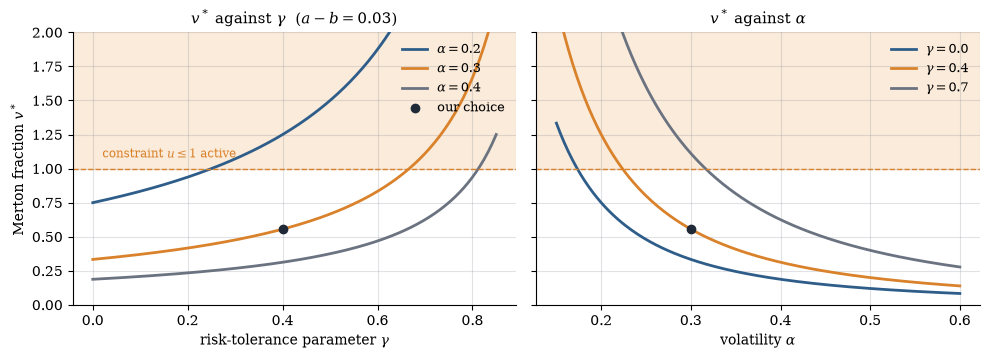

OK: Merton fraction is interior and solves the HJB equation analytically


In [4]:
vM = merton_control(a, b, alpha, gamma)
lam = merton_rate(a, b, alpha, gamma)
print(f"Merton fraction  v* = (a-b)/(alpha^2 (1-gamma)) = {vM:.6f}   (= 5/9 = {5/9:.6f})")
print(f"Value-function growth rate  lambda = {lam:.6f}")


def fig_merton_fraction(show=True):
    """Unconstrained Merton fraction as a function of gamma (varying alpha) and of alpha (varying gamma)."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.7), sharey=True)
    g = np.linspace(0.0, 0.85, 200)
    for al, col, ls in ((0.2, BLUE, "-"), (0.3, ORANGE, "-"), (0.4, GREY, "-")):
        ax1.plot(g, merton_unconstrained(a, b, al, g), color=col, ls=ls, lw=2, label=fr"$\alpha={al}$")
    ax1.scatter([gamma], [vM], color=DARK, zorder=4, label="our choice")
    ax1.set(xlabel=r"risk-tolerance parameter $\gamma$", ylabel=r"Merton fraction $v^*$",
            title=fr"$v^*$ against $\gamma$  ($a-b={a-b:.2f}$)", ylim=(0, 2))
    al_ = np.linspace(0.15, 0.6, 200)
    for gm, col in ((0.0, BLUE), (0.4, ORANGE), (0.7, GREY)):
        ax2.plot(al_, merton_unconstrained(a, b, al_, gm), color=col, lw=2, label=fr"$\gamma={gm}$")
    ax2.scatter([alpha], [vM], color=DARK, zorder=4)
    ax2.set(xlabel=r"volatility $\alpha$", title=r"$v^*$ against $\alpha$")
    for ax in (ax1, ax2):
        ax.axhspan(1, 2, color=LIGHT_ORANGE, alpha=0.7, zorder=0)
        ax.axhline(1, color=ORANGE, lw=1, ls="--")
        ax.legend(frameon=False, loc="upper right" if ax is ax1 else "upper right")
    ax1.text(0.02, 1.08, "constraint $u\\leq1$ active", color=ORANGE, fontsize=8.5)
    finish(fig, "merton_fraction", show)

fig_merton_fraction()

# --- test: v* maximises the HJB quadratic eta(v)/Phi = gamma (b + (a-b) v) - (1/2) alpha^2 gamma (1-gamma) v^2
vv = np.linspace(0.0, 1.0, 100001)
eta = gamma * (b + (a - b) * vv) - 0.5 * alpha**2 * gamma * (1 - gamma) * vv**2
assert 0.0 < vM < 1.0, "parameters must give an interior Merton fraction"
assert abs(vv[np.argmax(eta)] - vM) < 1e-4, "grid argmax of the HJB quadratic must match Merton's v*"
assert abs(eta.max() - lam) < 1e-9, "sup_v L^v Phi / Phi must equal lambda, i.e. Phi_t + sup L^v Phi = 0"
print("OK: Merton fraction is interior and solves the HJB equation analytically")

![Merton fraction against gamma and alpha](figures/merton_fraction.png)

*Merton's fraction grows with the excess return $a-b$ and with risk tolerance ($\gamma\uparrow$), and falls with volatility. In the shaded region the unconstrained optimum exceeds 1 and the constraint $u\le1$ would bind.*

## 5. Numerical strategy

Discretising the HJB equation with an *implicit* scheme (stable for any time step) leaves, at every time step, an equation of the form $\Phi-\Delta\tau\,\sup_v\mathcal{L}_h^v\Phi=\Phi^n$. The supremum makes it **nonlinear**: the maximising control depends on $\Phi$, so the matrix coefficients depend on the unknown and a single linear solve is not enough.

**Howard's policy iteration** removes that nonlinearity one linear problem at a time, and it has a clear economic reading: *freeze* a policy (a control at every node), *solve* the resulting linear problem to learn how good that policy is, *improve* the policy wherever it can be improved, and repeat. Mathematically it is exactly Newton's method applied to the HJB operator. In five lines (details in Appendix A):

- each implicit step is a nonlinear equation $G(\Phi)=\frac{\Phi-\Phi^n}{\Delta\tau}-\sup_v\mathcal{L}_h^v\Phi=0$;
- by Danskin's theorem the max operator is Fréchet differentiable wherever the maximiser is unique;
- its derivative is the *linear* operator $\mathcal{L}^{v^*}$, the generator with the control frozen at the maximiser, so $G'=\frac1{\Delta\tau}I-\mathcal{L}^{v^*}$;
- hence a Newton step is "freeze $v^*$, solve a linear system", which is precisely a policy-iteration step;
- the matrix of each linear system is an $M$-matrix, which guarantees a unique solution and a monotone scheme (a discrete comparison principle).

The recipe, step by step:

1. Reverse time, $\tau=T-t$, so the problem marches forward from $\Phi(\tau=0,x)=N(x)$.
2. Use **Backward Euler** in $\tau$ and an **upwind** finite-difference scheme in $x$: every step is a tridiagonal $M$-matrix system.
3. The sup makes each step nonlinear. **Howard's policy iteration** (equivalently, Newton on the HJB operator) handles it: freeze the control, solve the linear system, update the control, repeat.
4. Warm-start Howard with the control of the previous time step: it then typically needs 3–4 iterations.

![Policy-iteration loop](figures/hjb_idea.png)

*One time step: improve the policy in closed form, evaluate it with a linear solve, and loop until $\Phi$ stops changing.*

The theory behind steps 2–3 (Newton–Kantorovich, Danskin's theorem) is collected in [Appendix A](#appendix-a-theory).

## 6. Implementation

The solver is split into six small functions. Each is followed by a small test. Their data flow is

```text
build_mesh ─► compute_control ─► upwind_coefficients ─► assemble_system ─► solve_time_step ─► solve_hjb
   grid           step A             operator              step B           Howard loop       time loop
```

and, in more detail, `solve_hjb` is the outermost layer: it calls `build_mesh` once and then `solve_time_step` at every time step, which in turn calls `compute_control` and `assemble_system` (and, through it, `upwind_coefficients`) until Howard's loop converges. The names below are those of the code and of the diagram in Section 5.

- `build_mesh`: the space-time grid $(x_i,\tau_n)$ on which $\Phi$ is stored (Section 6.1).
- `compute_control`: **Howard step A, policy improvement** (box 1 of the diagram): the maximising control at every node, in closed form from the current iterate.
- `upwind_coefficients`: discretises $\mathcal{L}^v$ with the control frozen, producing `coef_lower`, `coef_main`, `coef_upper`.
- `assemble_system`: **Howard step B, policy evaluation** (box 2): builds the linear system $(I-\Delta\tau\,\mathcal{L}_h^{v})\Phi=\Phi^n$ plus the boundary rows; it is solved with `solve_banded` inside `solve_time_step`.
- `solve_time_step`: **Howard's loop for one time step**: alternates evaluation and improvement from a warm start, and tests convergence (box 3).
- `solve_hjb`: the orchestrator over time, from $\tau_0=0$ (terminal condition) to $\tau_{N_t}=T$, collecting the control and the iteration counts.

(`hjb_residual` is a diagnostic helper used only in the tests and in Figure 4b.)

### 6.1 Mesh

![Space-time mesh](figures/mesh.png)

*Nodes $(x_i,\tau_n)$. Boundary data (orange, grey) and the initial condition (blue) are imposed; every other node is advanced one implicit stencil at a time.*

In [5]:
def build_mesh(Xmax, T, Nx, Nt):
    """Uniform space-time mesh.

    Returns x (Nx+1 nodes in [0, Xmax]), tau (Nt+1 nodes in [0, T]), and the steps dx, dtau.
    Reversed time tau = T - t, so tau_0 = 0 corresponds to the terminal time t = T.
    """
    x = np.linspace(0.0, Xmax, Nx + 1)
    tau = np.linspace(0.0, T, Nt + 1)
    return x, tau, x[1] - x[0], tau[1] - tau[0]


x, tau, dx, dtau = build_mesh(Xmax, T, Nx, Nt)
assert x.shape == (Nx + 1,) and tau.shape == (Nt + 1,)
assert np.isclose(x[0], 0.0) and np.isclose(x[-1], Xmax) and np.isclose(tau[-1], T)
assert np.isclose(dx * Nx, Xmax) and np.isclose(dtau * Nt, T)
print(f"OK: mesh with dx = {dx:.3f}, dtau = {dtau:.3f}")

OK: mesh with dx = 0.100, dtau = 0.010


### 6.2 Policy improvement (Howard, step A)

At each interior node the supremum is over a quadratic $\eta(v)=\text{const}+x(a-b)\Phi_x\,v+\tfrac12\alpha^2x^2\Phi_{xx}\,v^2$. If $\Phi_{xx}<0$ we take the vertex and clip it to $[0,1]$. If $\Phi_{xx}\ge0$ the quadratic is convex or linear, so its maximum is at an endpoint and we compare $\eta(0)$ with $\eta(1)$ (the original code silently set $v=0$ there). Derivatives use central differences.

In [6]:
def compute_control(Phi, x, dx, a, b, alpha):
    """Howard step A (policy improvement): maximiser v in [0, 1] of L^v Phi at every node.

    Phi_x and Phi_xx come from central differences of the current iterate Phi. Where Phi_xx < 0 the
    maximiser is the clipped vertex -(a-b) Phi_x / (alpha^2 x Phi_xx); otherwise the quadratic in v is
    convex and the maximum is at v = 0 or v = 1. Boundary nodes copy their neighbour.
    """
    v = np.zeros_like(Phi)
    xi = x[1:-1]
    Phi_x = (Phi[2:] - Phi[:-2]) / (2.0 * dx)
    Phi_xx = (Phi[2:] - 2.0 * Phi[1:-1] + Phi[:-2]) / dx**2
    lin = (a - b) * xi * Phi_x                       # coefficient of v in L^v Phi
    quad = 0.5 * alpha**2 * xi**2 * Phi_xx           # coefficient of v^2
    concave = quad < 0.0
    vertex = -lin / (2.0 * np.where(concave, quad, -1.0))
    v[1:-1] = np.where(concave, np.clip(vertex, 0.0, 1.0), (lin + quad > 0.0).astype(float))
    v[0], v[-1] = v[1], v[-2]
    return v


# test 1: for CRRA data the control is Merton's fraction away from the singular point x = 0
Phi0 = N_func(x)
v0 = compute_control(Phi0, x, dx, a, b, alpha)
away = x >= 0.1 * Xmax
assert np.all((v0 >= 0) & (v0 <= 1))
assert np.max(np.abs(v0[away] - vM)) < 2e-2, np.max(np.abs(v0[away] - vM))
# test 2: convex data (Phi = x^2) must give a bang-bang control, 0 or 1
v_convex = compute_control(x**2, x, dx, a, b, alpha)
assert set(np.unique(v_convex[1:-1])) <= {0.0, 1.0}
print(f"OK: max |v - v*| on x >= {0.1*Xmax:g} for Phi = N(x): {np.max(np.abs(v0[away]-vM)):.2e}")

OK: max |v - v*| on x >= 1 for Phi = N(x): 1.04e-03


### 6.3 Matrix assembly (Howard, step B)

With $c_i=(b+(a-b)v_i)x_i\ge0$ and $d_i=\tfrac12\alpha^2v_i^2x_i^2$, the upwind operator at node $i$ has the coefficients
$$A_i=\tfrac{d_i}{\Delta x^2}-\tfrac{c_i^-}{\Delta x},\quad C_i=\tfrac{d_i}{\Delta x^2}+\tfrac{c_i^+}{\Delta x},\quad B_i=-A_i-C_i,$$
called `coef_lower`, `coef_main`, `coef_upper` in the code. Interior rows are $-\Delta\tau A_i\Phi_{i-1}+(1-\Delta\tau B_i)\Phi_i-\Delta\tau C_i\Phi_{i+1}=\Phi_i^n$. The boundary rows are $\Phi_0=N(0)$ and, at $x=X_{\max}$, the first-order extrapolation $\Phi_{N_x}=\Phi_{N_x-1}$, i.e. the row $(\dots,-1,1)$. The $(1,-2,1)$ row used in the original code is the standard second-order extrapolation closure ($\Phi_{xx}=0$ at the boundary); it is rejected here because it puts a positive off-diagonal entry in the last row and so breaks the $M$-matrix property. First-order extrapolation keeps the matrix an $M$-matrix.

![Upwind stencil](figures/upwind_stencil.png)

*Left: the implicit stencil that produces one row of the matrix. Right: the one-sided difference is chosen in the direction the drift points.*

In [7]:
def upwind_coefficients(v, x, dx, a, b, alpha):
    """Upwind coefficients (coef_lower, coef_main, coef_upper) of the discrete operator L_h^v.

    (L_h^v Phi)_i = coef_lower_i Phi_{i-1} + coef_main_i Phi_i + coef_upper_i Phi_{i+1}.
    """
    c = (b + (a - b) * v) * x                  # drift coefficient
    d = 0.5 * alpha**2 * v**2 * x**2           # diffusion coefficient
    coef_lower = d / dx**2 - np.minimum(c, 0.0) / dx
    coef_upper = d / dx**2 + np.maximum(c, 0.0) / dx
    coef_main = -coef_lower - coef_upper
    return coef_lower, coef_main, coef_upper


def assemble_system(v, x, dx, dtau, a, b, alpha, Phi_n, N0):
    """Howard step B: tridiagonal system M Phi = rhs for (I - dtau L_h^v) Phi = Phi^n plus boundary rows.

    M is returned in the banded storage used by scipy.linalg.solve_banded:
    ab[0, 1:] = superdiagonal, ab[1, :] = diagonal, ab[2, :-1] = subdiagonal.
    Row 0 is the Dirichlet condition Phi_0 = N0; the last row is Phi_Nx - Phi_{Nx-1} = 0.
    """
    Nx = x.size - 1
    coef_lower, coef_main, coef_upper = upwind_coefficients(v, x, dx, a, b, alpha)
    ab = np.zeros((3, Nx + 1))
    ab[1, :] = 1.0 - dtau * coef_main
    ab[2, :-1] = -dtau * coef_lower[1:]
    ab[0, 1:] = -dtau * coef_upper[:-1]
    rhs = Phi_n.copy()
    ab[1, 0], ab[0, 1], rhs[0] = 1.0, 0.0, N0                 # Dirichlet at x = 0
    ab[1, Nx], ab[2, Nx - 1], rhs[Nx] = 1.0, -1.0, 0.0        # Phi_Nx = Phi_{Nx-1} at x = Xmax
    return ab, rhs


def banded_to_dense(ab):
    """Dense matrix from the banded storage (only used for tests and inspection)."""
    return np.diag(ab[1]) + np.diag(ab[0, 1:], 1) + np.diag(ab[2, :-1], -1)


ab, rhs = assemble_system(v0, x, dx, dtau, a, b, alpha, Phi0, N0)
M = banded_to_dense(ab)
off = M - np.diag(np.diag(M))
assert np.all(np.diag(M) > 0) and np.all(off <= 0), "M must be a Z-matrix with positive diagonal"
assert np.allclose(M[1:-1].sum(axis=1), 1.0), "interior rows sum to 1 (constants are reproduced)"
assert np.all(np.linalg.inv(M) >= -1e-12), "M must be an M-matrix: its inverse is entrywise non-negative"
# the (1, -2, 1) closure of the original code is NOT a Z-matrix (positive entry in the last row)
M_old = M.copy()
M_old[-1, :] = 0.0
M_old[-1, -3:] = [1.0, -2.0, 1.0]
assert (M_old - np.diag(np.diag(M_old))).max() > 0
print("OK: assembled matrix is an M-matrix; the old (1,-2,1) boundary row would break this property")

OK: assembled matrix is an M-matrix; the old (1,-2,1) boundary row would break this property


### 6.4 One time step: Howard's loop

We start from the control of the previous time level (warm start), solve, update the control from the new iterate, and stop when $\Phi$ no longer changes. The number of iterations is recorded and `converged` is returned, so a failure to converge can be reported instead of passing silently.

To measure progress we use the residual of the full discrete nonlinear system (interior rows and both boundary rows),
$R(\Phi)=\bigl(\Phi-\Delta\tau\,\mathcal{L}_h^{v(\Phi)}\Phi-\Phi^n\bigr)$ in the interior and the boundary equations at the two ends, in the maximum norm.

In [8]:
def hjb_residual(Phi, Phi_n, x, dx, dtau, a, b, alpha, N0):
    """Max-norm residual of the discrete nonlinear system (all rows) with v = v(Phi)."""
    v = compute_control(Phi, x, dx, a, b, alpha)
    cl, cm, cu = upwind_coefficients(v, x, dx, a, b, alpha)
    r = np.empty_like(Phi)
    r[1:-1] = Phi[1:-1] - dtau * (cl[1:-1] * Phi[:-2] + cm[1:-1] * Phi[1:-1] + cu[1:-1] * Phi[2:]) - Phi_n[1:-1]
    r[0] = Phi[0] - N0
    r[-1] = Phi[-1] - Phi[-2]
    return np.max(np.abs(r))


def solve_time_step(Phi_n, v_warm, x, dx, dtau, a, b, alpha, N0, tol=1e-10, max_iter=100):
    """Advance one implicit time step with Howard's policy iteration.

    Parameters
    ----------
    Phi_n : value function at the previous time level.
    v_warm : control of the previous time level, used as the initial policy (warm start).
    tol : stop when max|Phi^(k+1) - Phi^(k)| < tol * (1 + max|Phi|).

    Returns
    -------
    Phi : value function at the new time level.
    v : control computed from the final Phi.
    n_iter : number of Howard iterations used.
    converged : False if max_iter was reached without meeting tol.
    """
    v = v_warm.copy()
    Phi_k = Phi_n.copy()
    for k in range(1, max_iter + 1):
        ab, rhs = assemble_system(v, x, dx, dtau, a, b, alpha, Phi_n, N0)
        Phi_new = solve_banded((1, 1), ab, rhs)                    # step B + C: linear solve
        change = np.max(np.abs(Phi_new - Phi_k))
        Phi_k = Phi_new
        v = compute_control(Phi_k, x, dx, a, b, alpha)             # step A: policy improvement
        if change < tol * (1.0 + np.max(np.abs(Phi_k))):
            return Phi_k, v, k, True
    return Phi_k, v, max_iter, False


# test: the residual falls monotonically and superlinearly along Howard's iteration (first time step)
Phi_k, res = Phi0.copy(), []
for k in range(5):
    res.append(hjb_residual(Phi_k, Phi0, x, dx, dtau, a, b, alpha, N0))
    ab, rhs = assemble_system(compute_control(Phi_k, x, dx, a, b, alpha), x, dx, dtau, a, b, alpha, Phi0, N0)
    Phi_k = solve_banded((1, 1), ab, rhs)
print("Howard residuals, first time step:", " -> ".join(f"{r:.1e}" for r in res))
assert res[1] < res[0], "a single Howard step must decrease the residual"
assert all(np.diff(res) < 0) and res[-1] < 1e-3 * res[0], "residual must decrease monotonically and fast"

Phi1, v1, n_it, ok = solve_time_step(Phi0, v0, x, dx, dtau, a, b, alpha, N0)
assert ok and n_it < 20, (ok, n_it)
assert hjb_residual(Phi1, Phi0, x, dx, dtau, a, b, alpha, N0) < 1e-8
print(f"OK: first time step converged in {n_it} Howard iterations")

Howard residuals, first time step: 2.5e-02 -> 1.9e-02 -> 1.8e-04 -> 1.8e-05 -> 3.8e-07
OK: first time step converged in 7 Howard iterations


### 6.5 Time marching and the full solver

`solve_hjb` builds the mesh, initialises $\Phi^0=N(x)$ and the control at $\tau=0$, and calls `solve_time_step` for $n=0,\dots,N_t-1$. It issues a warning if any time step fails to converge, and returns the control at every node together with the Howard iteration counts.

In [9]:
@dataclass
class HJBSolution:
    """Output of solve_hjb. Row n of `control` corresponds to tau_n = n dtau, i.e. t = T - tau_n."""
    x: np.ndarray
    tau: np.ndarray
    control: np.ndarray     # shape (Nt + 1, Nx + 1)
    Phi: np.ndarray         # value function at tau = T (t = 0), shape (Nx + 1,)
    iters: np.ndarray       # Howard iterations per time step, shape (Nt,)


def solve_hjb(a, b, alpha, N_func, Xmax, T, Nx, Nt, tol=1e-10, max_iter=100):
    """Solve the Merton HJB equation: Backward Euler + upwind + Howard policy iteration."""
    x, tau, dx, dtau = build_mesh(Xmax, T, Nx, Nt)
    Phi = np.asarray(N_func(x), dtype=float)
    N0 = float(N_func(0.0))
    control = np.zeros((Nt + 1, Nx + 1))
    iters = np.zeros(Nt, dtype=int)
    control[0] = compute_control(Phi, x, dx, a, b, alpha)
    for n in range(Nt):
        Phi, v, iters[n], converged = solve_time_step(Phi, control[n], x, dx, dtau, a, b, alpha, N0, tol, max_iter)
        if not converged:
            warnings.warn(f"Howard iteration did not converge at time step {n} (max_iter={max_iter})")
        control[n + 1] = v
    return HJBSolution(x, tau, control, Phi, iters)


t0 = time.perf_counter()
sol = solve_hjb(a, b, alpha, N_func, Xmax, T, Nx, Nt)
elapsed = time.perf_counter() - t0

assert sol.control.shape == (Nt + 1, Nx + 1) and sol.iters.shape == (Nt,)
assert np.all((sol.control >= 0) & (sol.control <= 1))
assert sol.iters.max() < 100, "Howard hit max_iter at some time step"
assert np.all(np.diff(sol.Phi) >= -1e-12) and sol.Phi[0] == N0, "Phi must be non-decreasing in x with Phi(0)=N(0)"
print(f"OK: solved {Nx}x{Nt} problem in {elapsed:.2f} s; Howard iterations per step: "
      f"min {sol.iters.min()}, mean {sol.iters.mean():.2f}, max {sol.iters.max()}")

OK: solved 100x100 problem in 0.03 s; Howard iterations per step: min 3, mean 3.12, max 7


## 7. Experiments and validation

We validate on the interior $0.1X_{\max}\le x\le 0.5X_{\max}$. Near $x=0$ the CRRA value function behaves like $x^\gamma$ with an unbounded derivative, which central differences resolve poorly; near $X_{\max}$ the artificial boundary condition contaminates the solution (Section 8). The interior is where the numerical control should match Merton's constant fraction: if the scheme is correct, in the interior the numerical control must be flat and equal to $v^*$ at every time level. We stop at $0.5X_{\max}$ rather than, say, $0.8X_{\max}$ to leave a margin for the boundary layer produced by the artificial condition at $X_{\max}$, which propagates inwards as time marches.

**What to expect (Figure 1).** A flat white band across the whole interior (the colour scale is centred at Merton's $v^*$) and a coloured artefact near $x=X_{\max}$ produced by the artificial boundary condition (discussed in Section 8), growing as we march away from $t=T$.

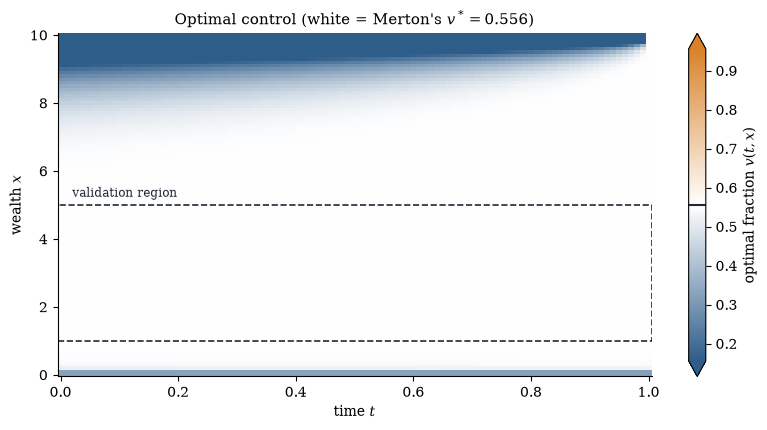

In [10]:
sol = solve_hjb(a, b, alpha, N_func, Xmax, T, Nx, Nt)
x = sol.x
interior = (x >= 0.1 * Xmax) & (x <= 0.5 * Xmax)
t_grid = T - sol.tau            # physical time of each row of sol.control (row 0 is t = T)


def fig_heatmap(sol, show=True):
    """Figure 1: heatmap of the optimal control v(t, x)."""
    t = T - sol.tau
    order = np.argsort(t)       # plot with t increasing from 0 to T
    fig, ax = plt.subplots(figsize=(8.2, 4.4))
    mesh = ax.pcolormesh(t[order], sol.x, sol.control[order].T, cmap=CMAP_DIV, shading="nearest",
                         vmin=vM - 0.4, vmax=vM + 0.4)
    cb = fig.colorbar(mesh, ax=ax, extend="both")
    cb.set_label("optimal fraction $v(t,x)$")
    cb.ax.axhline(vM, color=DARK, lw=1.5)
    ax.axhspan(0.1 * Xmax, 0.5 * Xmax, facecolor="none", edgecolor=DARK, ls="--", lw=1.2)
    ax.text(0.02 * T, 0.5 * Xmax + 0.15, "validation region", fontsize=8.5, color=DARK, va="bottom")
    ax.set(xlabel="time $t$", ylabel="wealth $x$", title=f"Optimal control (white = Merton's $v^*={vM:.3f}$)")
    ax.grid(False)
    finish(fig, "fig1_control_heatmap", show)

fig_heatmap(sol)

**Figure 1.** In the interior the control is the constant Merton fraction at every time. The deviation near $x=X_{\max}$ grows as time runs backwards from $T$: it is a numerical boundary layer created by the extrapolation condition and propagating inwards by diffusion.

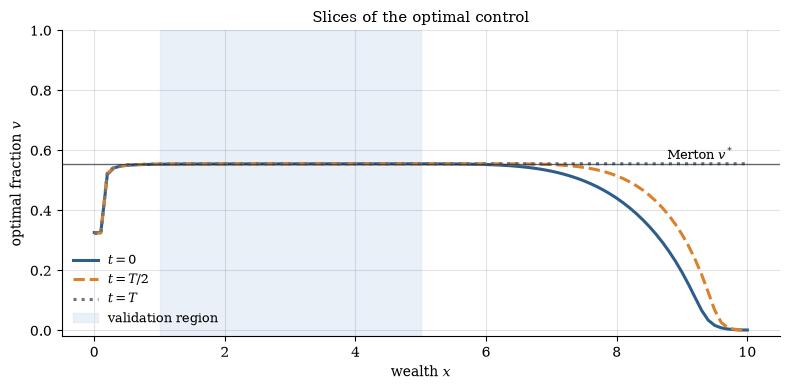

In [11]:
def fig_slices(sol, show=True):
    """Figure 2: v against x at t = 0, T/2, T."""
    fig, ax = plt.subplots(figsize=(8, 4))
    Nt_ = sol.control.shape[0] - 1
    for row, lab, col, ls in ((Nt_, "$t=0$", BLUE, "-"), (Nt_ // 2, "$t=T/2$", ORANGE, "--"), (0, "$t=T$", GREY, ":")):
        ax.plot(sol.x, sol.control[row], color=col, ls=ls, lw=2.2, label=lab)
    ax.axhline(vM, color=DARK, lw=1, alpha=0.7)
    ax.text(0.98 * Xmax, vM + 0.015, "Merton $v^*$", ha="right", fontsize=9)
    ax.axvspan(0.1 * Xmax, 0.5 * Xmax, color=LIGHT_BLUE, alpha=0.6, zorder=0, label="validation region")
    ax.set(xlabel="wealth $x$", ylabel="optimal fraction $v$", ylim=(-0.02, 1.0), title="Slices of the optimal control")
    ax.legend(frameon=False, loc="lower left")
    finish(fig, "fig2_control_slices", show)

fig_slices(sol)

**Figure 2.** At $t=T$ the control is computed directly from the terminal utility and is accurate up to $x\approx X_{\max}$. As $t$ decreases (more time marched), the boundary layer at $X_{\max}$ widens, while the plateau at $v^*$ in the validation region remains intact.

**What to expect (Figure 3).** The numerical control should lie on top of the dashed Merton line (left), with errors of order $10^{-3}$ or smaller, and the relative error of the value function should be a few times $10^{-4}$ (right).

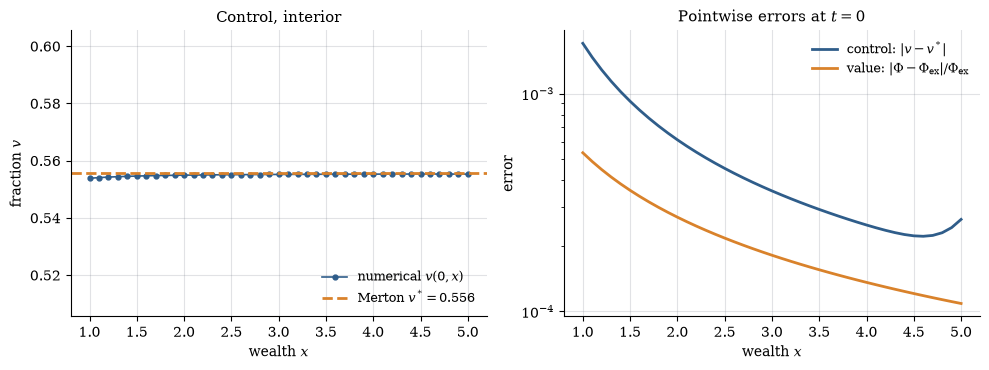

max |v_num - v*| over interior and all time levels : 1.70e-03
max relative error of Phi(0, x) on the interior     : 5.34e-04
OK: numerical solution matches Merton in the interior


In [12]:
def fig_validation(sol, show=True):
    """Figure 3: numerical vs analytical control and value function in the interior."""
    xs = sol.x
    mask = (xs >= 0.1 * Xmax) & (xs <= 0.5 * Xmax)
    v_num = sol.control[-1]                                           # t = 0
    Phi_ex = merton_value(0.0, xs, T, a, b, alpha, gamma)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.8))
    ax1.plot(xs[mask], v_num[mask], "o-", color=BLUE, ms=3.5, lw=1.2, label="numerical $v(0,x)$")
    ax1.axhline(vM, color=ORANGE, ls="--", lw=2, label=f"Merton $v^*={vM:.3f}$")
    ax1.set(xlabel="wealth $x$", ylabel="fraction $v$", ylim=(vM - 0.05, vM + 0.05), title="Control, interior")
    ax1.legend(frameon=False, loc="lower right")
    ax2.semilogy(xs[mask], np.abs(v_num[mask] - vM), color=BLUE, lw=2, label=r"control: $|v-v^*|$")
    ax2.semilogy(xs[mask], np.abs(sol.Phi[mask] - Phi_ex[mask]) / Phi_ex[mask], color=ORANGE, lw=2,
                 label=r"value: $|\Phi-\Phi_{\mathrm{ex}}|/\Phi_{\mathrm{ex}}$")
    ax2.set(xlabel="wealth $x$", ylabel="error", title="Pointwise errors at $t=0$")
    ax2.legend(frameon=False)
    finish(fig, "fig3_validation", show)

fig_validation(sol)

# --- test: numerical control and value function agree with Merton in the interior
err_v = np.max(np.abs(sol.control[1:][:, interior] - vM))
Phi_ex = merton_value(0.0, x, T, a, b, alpha, gamma)
err_Phi = np.max(np.abs(sol.Phi[interior] - Phi_ex[interior]) / Phi_ex[interior])
print(f"max |v_num - v*| over interior and all time levels : {err_v:.2e}")
print(f"max relative error of Phi(0, x) on the interior     : {err_Phi:.2e}")
assert err_v < 1e-2 and err_Phi < 5e-3
print("OK: numerical solution matches Merton in the interior")

**Figure 3.** On the validation region the numerical control sits on top of Merton's constant (left), with control errors of order $10^{-3}$ and relative value-function errors of a few $10^{-4}$ (right).

**What to expect (Figure 4).** Only a handful of Howard iterations per time step: the largest count at the first step, where the initial policy comes only from $N$, and an almost constant count afterwards thanks to the warm start.

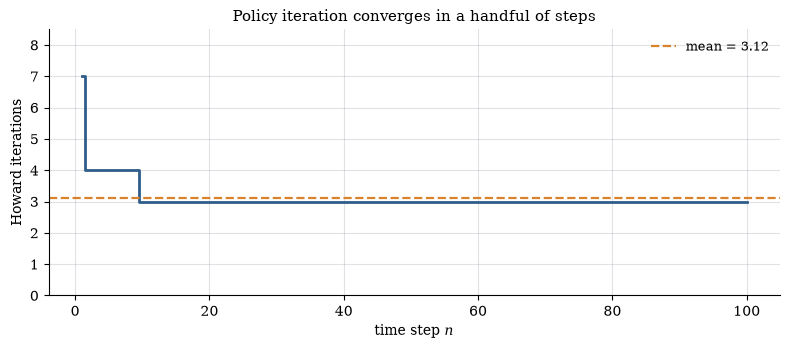

OK: first step took 7 iterations, later steps at most 4


In [13]:
def fig_iterations(sol, show=True):
    """Figure 4: Howard iterations needed at each time step."""
    fig, ax = plt.subplots(figsize=(8, 3.6))
    steps = np.arange(1, sol.iters.size + 1)
    ax.step(steps, sol.iters, where="mid", color=BLUE, lw=2)
    ax.axhline(sol.iters.mean(), color=ORANGE, ls="--", lw=1.6, label=f"mean = {sol.iters.mean():.2f}")
    ax.set(xlabel="time step $n$", ylabel="Howard iterations", ylim=(0, sol.iters.max() + 1.5),
           title="Policy iteration converges in a handful of steps")
    ax.legend(frameon=False)
    finish(fig, "fig4_howard_iterations", show)

fig_iterations(sol)
assert sol.iters[1:].max() <= 6 and sol.iters.mean() < 5
print(f"OK: first step took {sol.iters[0]} iterations, later steps at most {sol.iters[1:].max()}")

**Figure 4.** The first step needs the most iterations (the initial policy comes from $N$ alone). Afterwards the warm start keeps every step at 3–4 iterations. This count says *how many* iterations the tolerance requires, not *how fast* the iteration converges; Figure 4b looks inside single time steps to show the rate.

**What to expect (Figure 4b).** If Howard's method is Newton's method, the residual of the discrete HJB system should drop by several orders of magnitude per iteration, down to rounding level.

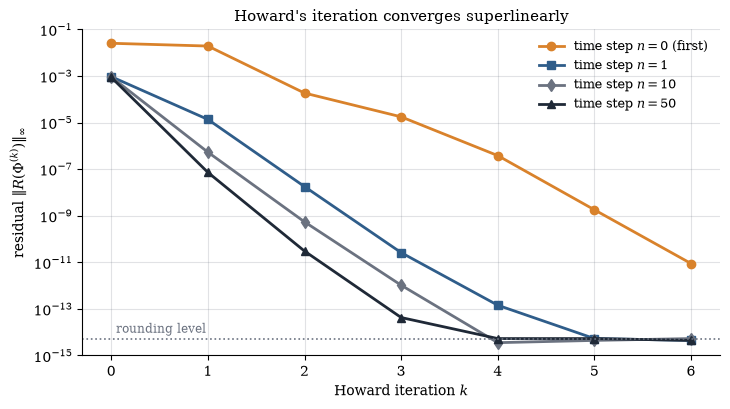

OK: residual after 3 Howard iterations vs initial: {0: '7.0e-04', 1: '2.8e-08', 10: '1.1e-09', 50: '4.9e-11'}


In [14]:

def fig_howard_residuals(steps=(0, 1, 10, 50), n_iter=6, show=True):
    """Figure 4b: residual of the discrete HJB system along Howard's iteration (log scale).

    Reuses the solver functions unchanged: march to each requested time step with solve_time_step,
    then replay Howard's loop from the warm-start policy and record hjb_residual at every iterate.
    """
    xs, _, dx_, dtau_ = build_mesh(Xmax, T, Nx, Nt)
    Phi_n = np.asarray(N_func(xs), dtype=float)
    v_n = compute_control(Phi_n, xs, dx_, a, b, alpha)
    histories = {}
    for n in range(max(steps) + 1):
        if n in steps:
            Phi_k, v_k = Phi_n.copy(), v_n.copy()
            hist = [hjb_residual(Phi_k, Phi_n, xs, dx_, dtau_, a, b, alpha, N0)]
            for _ in range(n_iter):
                ab_, rhs_ = assemble_system(v_k, xs, dx_, dtau_, a, b, alpha, Phi_n, N0)
                Phi_k = solve_banded((1, 1), ab_, rhs_)
                v_k = compute_control(Phi_k, xs, dx_, a, b, alpha)
                hist.append(hjb_residual(Phi_k, Phi_n, xs, dx_, dtau_, a, b, alpha, N0))
            histories[n] = np.array(hist)
        Phi_n, v_n, _, _ = solve_time_step(Phi_n, v_n, xs, dx_, dtau_, a, b, alpha, N0)

    fig, ax = plt.subplots(figsize=(7.4, 4.2))
    for (n, hist), col, mk in zip(histories.items(), (ORANGE, BLUE, GREY, DARK), "osd^"):
        ax.semilogy(np.arange(hist.size), np.maximum(hist, 1e-16), marker=mk, color=col, lw=2,
                    label=f"time step $n={n}$" + (" (first)" if n == 0 else ""))
    ax.axhline(5e-15, color=GREY, ls=":", lw=1.2)
    ax.text(0.05, 7e-15, "rounding level", ha="left", va="bottom", fontsize=8.5, color=GREY)
    ax.set(xlabel="Howard iteration $k$", ylabel=r"residual $\|R(\Phi^{(k)})\|_\infty$",
           title="Howard's iteration converges superlinearly", ylim=(1e-15, 1e-1))
    ax.legend(frameon=False)
    finish(fig, "fig4b_howard_residuals", show)
    return histories


howard_hist = fig_howard_residuals()
assert all(h[3] < 1e-3 * h[0] for h in howard_hist.values()), "residual must drop fast along Howard's iteration"
print("OK: residual after 3 Howard iterations vs initial:",
      {n: f"{h[3] / h[0]:.1e}" for n, h in howard_hist.items()})


**Figure 4b.** On a log scale the residual of the discrete HJB system falls by several orders of magnitude per iteration until it reaches the rounding level ($\sim5\cdot10^{-15}$): far faster than the constant reduction factor per iteration that linear convergence would give, as expected for Newton's method (superlinear convergence). The first time step ($n=0$) is slower: its starting residual is dominated by the boundary row at $x=X_{\max}$, which the initial iterate $\Phi^0=N$ does not satisfy.

**What to expect (convergence table).** Upwind is first order in space and Backward Euler is first order in time, and we refine both together ($N_t=N_x$), so we expect an observed order close to 1 (somewhat higher for the control, which is a ratio of derivatives of $\Phi$ that benefits from error cancellation).

 Nx=Nt       dx   max|v-v*|  order  rel. err Phi  order  it/step  time [s]
    25   0.4000    1.41e-02    nan      1.69e-03    nan     4.12      0.01
    50   0.2000    5.40e-03   1.38      1.04e-03   0.70     3.36      0.02
   100   0.1000    1.70e-03   1.67      5.34e-04   0.96     3.12      0.03
   200   0.0500    6.13e-04   1.47      2.71e-04   0.98     3.04      0.06
   400   0.0250    2.49e-04   1.30      1.37e-04   0.99     3.02      0.14


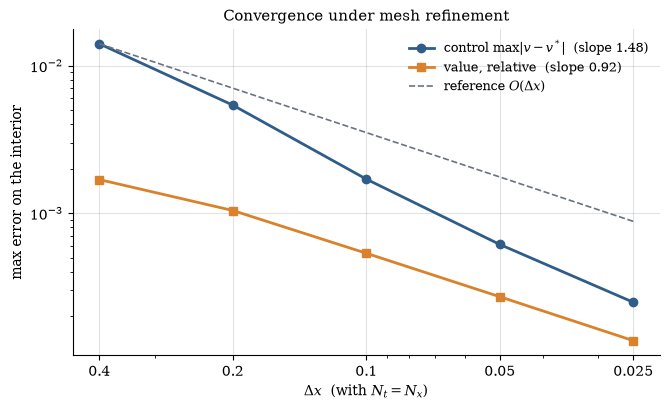

OK: errors decrease monotonically; fitted orders 1.48 (control), 0.92 (value)


In [15]:
def convergence_study(sizes=(25, 50, 100, 200, 400)):
    """Solve with Nx = Nt = n for several n; return max interior errors against Merton."""
    rows = []
    for n in sizes:
        t0 = time.perf_counter()
        s = solve_hjb(a, b, alpha, N_func, Xmax, T, n, n)
        elapsed = time.perf_counter() - t0
        xs = s.x
        m = (xs >= 0.1 * Xmax) & (xs <= 0.5 * Xmax)
        Phi_ex = merton_value(0.0, xs, T, a, b, alpha, gamma)
        rows.append(dict(n=n, dx=Xmax / n,
                         err_v=np.max(np.abs(s.control[1:][:, m] - vM)),
                         err_Phi=np.max(np.abs(s.Phi[m] - Phi_ex[m]) / Phi_ex[m]),
                         iters=s.iters.mean(), seconds=elapsed))
    return rows


def print_table(rows):
    """Validation table with observed convergence orders."""
    print(f"{'Nx=Nt':>6} {'dx':>8} {'max|v-v*|':>11} {'order':>6} {'rel. err Phi':>13} {'order':>6} {'it/step':>8} {'time [s]':>9}")
    for k, r in enumerate(rows):
        if k:
            ov = np.log2(rows[k - 1]["err_v"] / r["err_v"])
            oP = np.log2(rows[k - 1]["err_Phi"] / r["err_Phi"])
        else:
            ov = oP = float("nan")
        print(f"{r['n']:>6d} {r['dx']:>8.4f} {r['err_v']:>11.2e} {ov:>6.2f} {r['err_Phi']:>13.2e} {oP:>6.2f} "
              f"{r['iters']:>8.2f} {r['seconds']:>9.2f}")


def fig_convergence(rows, show=True):
    """Figure 5: max interior error against dx (log-log) with fitted order."""
    dxs = np.array([r["dx"] for r in rows])
    ev = np.array([r["err_v"] for r in rows])
    eP = np.array([r["err_Phi"] for r in rows])
    sv, sP = np.polyfit(np.log(dxs), np.log(ev), 1)[0], np.polyfit(np.log(dxs), np.log(eP), 1)[0]
    fig, ax = plt.subplots(figsize=(6.8, 4.2))
    ax.loglog(dxs, ev, "o-", color=BLUE, lw=2, label=fr"control $\max|v-v^*|$  (slope {sv:.2f})")
    ax.loglog(dxs, eP, "s-", color=ORANGE, lw=2, label=fr"value, relative  (slope {sP:.2f})")
    ax.loglog(dxs, ev[0] * (dxs / dxs[0]), color=GREY, ls="--", lw=1.2, label=r"reference $O(\Delta x)$")
    ax.invert_xaxis()
    ax.set_xticks(dxs)
    ax.set_xticklabels([f"{d:g}" for d in dxs])
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set(xlabel=r"$\Delta x$  (with $N_t=N_x$)", ylabel="max error on the interior", title="Convergence under mesh refinement")
    ax.legend(frameon=False)
    finish(fig, "fig5_convergence", show)
    return sv, sP


rows = convergence_study()
print_table(rows)
slope_v, slope_P = fig_convergence(rows)
assert all(rows[k]["err_v"] > rows[k + 1]["err_v"] for k in range(len(rows) - 1)), "control error must decrease"
assert all(rows[k]["err_Phi"] > rows[k + 1]["err_Phi"] for k in range(len(rows) - 1)), "value error must decrease"
assert slope_v > 0.9 and slope_P > 0.8, (slope_v, slope_P)
print(f"OK: errors decrease monotonically; fitted orders {slope_v:.2f} (control), {slope_P:.2f} (value)")

**Figure 5 and table.** The error decreases monotonically under refinement with an observed order at least 1 for the control and close to 1 for the value function, in agreement with the first-order upwind scheme and Backward Euler (here $\Delta\tau\propto\Delta x$). The cost grows linearly with $N_x N_t$.

## 8. Discussion and limitations

- **Artificial boundary at $X_{\max}$.** The true problem lives on $x\in(0,\infty)$. Truncating at $X_{\max}$ and imposing $\Phi_{N_x}=\Phi_{N_x-1}$ (zero slope) is wrong for the CRRA value function, whose slope there is $\Phi_x=X_{\max}^{\gamma-1}e^{\lambda(T-t)}>0$. The mismatch creates a boundary layer that spreads inwards at a rate set by diffusion (about $\alpha v^* x\sqrt{T}$), which is why we validate away from $X_{\max}$ and why $X_{\max}$ should be taken well above the wealth levels of interest. The $(1,-2,1)$ closure of the original notebook (the standard second-order extrapolation, i.e. $\Phi_{xx}=0$ at the boundary) is rejected because its positive off-diagonal entry breaks the $M$-matrix property (Section 6.3); first-order extrapolation keeps it.
- **Singularity at $x=0$.** For $\gamma<1$, $\Phi_x\sim x^{\gamma-1}$ is unbounded at $0$, so central differences are inaccurate in the first cells.
- **Upwind numerical diffusion, $O(\Delta x)$.** The upwind drift adds an artificial diffusion of order $c\,\Delta x/2$. This is the price for monotonicity (the $M$-matrix property that makes policy iteration well posed). Second-order monotone schemes exist but are more involved.
- **Time stepping.** Backward Euler is first-order in $\Delta\tau$ but unconditionally stable, so the step is chosen for accuracy, not stability.
- **Assumption $b\ge0$.** It makes the drift $c_i\ge0$ everywhere, so the upwind direction is fixed; for $b<0$ the sign of $c$ can change with $v$ and the choice of one-sided difference must be made jointly with the maximisation.
- **Extensions.** (i) Transaction costs, which turn the HJB equation into a variational inequality with gradient constraints. (ii) Problems where the control enters linearly, giving bang-bang optimal controls, for which policy iteration still applies but the closed form of Step A is replaced by a comparison of endpoints. (iii) Obstacle problems (optimal stopping, American-type features), solved with the same Howard idea applied to $\min\{\,\cdot\,,\Phi-\psi\}$.

### Reproduce everything

The notebook can be run cell by cell: each cell is self-contained given the cells before it, so you can stop after any section and inspect the variables. The final code cell, `reproduce_all()`, regenerates the figures of Sections 2–7 in `./figures/` and prints the validation table, so every result can be reproduced with one call. (Figure 4b, a companion diagnostic to Figure 4, is produced by its own cell in Section 7.)

In [16]:
def reproduce_all(show=False):
    """Regenerate all figures and print the validation table."""
    for f in (fig_problem, fig_hjb_idea, fig_upwind_stencil, fig_mesh, fig_wealth_paths, fig_merton_fraction):
        f(show)
    s = solve_hjb(a, b, alpha, N_func, Xmax, T, Nx, Nt)
    for f in (fig_heatmap, fig_slices, fig_validation, fig_iterations):
        f(s, show)
    table = convergence_study()
    fig_convergence(table, show)
    print_table(table)
    assert table[-1]["err_v"] < table[0]["err_v"]
    print("\nAll figures regenerated in ./figures:")
    for name in sorted(os.listdir("figures")):
        print("  ", name)


if __name__ == "__main__":
    reproduce_all()

 Nx=Nt       dx   max|v-v*|  order  rel. err Phi  order  it/step  time [s]
    25   0.4000    1.41e-02    nan      1.69e-03    nan     4.12      0.01
    50   0.2000    5.40e-03   1.38      1.04e-03   0.70     3.36      0.02
   100   0.1000    1.70e-03   1.67      5.34e-04   0.96     3.12      0.03
   200   0.0500    6.13e-04   1.47      2.71e-04   0.98     3.04      0.07
   400   0.0250    2.49e-04   1.30      1.37e-04   0.99     3.02      0.14

All figures regenerated in ./figures:
   fig1_control_heatmap.png
   fig2_control_slices.png
   fig3_validation.png
   fig4_howard_iterations.png
   fig4b_howard_residuals.png
   fig5_convergence.png
   hjb_idea.png
   merton_fraction.png
   mesh.png
   problem.png
   upwind_stencil.png
   wealth_paths.png


## Appendix A: theory

This appendix keeps the derivations of the original notebook (translated and reorganised). It is not needed to run or read the main body.

### A.1 Differential operator, HJB equation and optimal control

For a frozen control $v$ the generator of the wealth process, including time, is
$$(L^v f)(t,x)=\frac{\partial f}{\partial t}+x\bigl(av+b(1-v)\bigr)\frac{\partial f}{\partial x}+\frac12\alpha^2v^2x^2\frac{\partial^2 f}{\partial x^2}= f_t+\mathcal{L}^vf .$$
The value function $\Phi(s,x)=\sup_{u}\mathbb{E}^{s,x}[N(X_T^u)]$ over Markov controls $0\le u\le1$ satisfies
$$\sup_{v\in[0,1]}(L^v\Phi)(t,x)=0\ \text{in } G=\{t<T,\ x>0\},\qquad \Phi(T,x)=N(x),\ \ \Phi(t,0)=N(0).$$
(The notebook this material derives from writes $t_0$ for the horizon; here it is $T$ throughout, and this is the only place where $t_0$ is mentioned.) For fixed $(t,x)$ maximise
$$\eta(v)=\Phi_t+x\bigl(b+(a-b)v\bigr)\Phi_x+\tfrac12\alpha^2v^2x^2\Phi_{xx}.$$
If $\Phi_x>0$ and $\Phi_{xx}<0$, $\eta$ is a concave parabola with vertex
$$v=-\frac{(a-b)\Phi_x}{\alpha^2x\Phi_{xx}},$$
which is then clipped to $[0,1]$. The case $\Phi_{xx}\ge0$ has to be treated by comparing the endpoints.

### A.2 Newton–Raphson for the HJB operator

Write the HJB equation as $F(\Phi)=\sup_{v\in[0,1]}L^v\Phi=0$. In a Banach space, given $\Phi^{(0)}$, Newton–Kantorovich iterates
$$F(\Phi^{(k)})+F'(\Phi^{(k)})[\Phi^{(k+1)}-\Phi^{(k)}]=0 .$$
With the step $\delta^{(k)}=\Phi^{(k+1)}-\Phi^{(k)}$ this is $F'(\Phi^{(k)})[\delta^{(k)}]=-F(\Phi^{(k)})$, followed by $\Phi^{(k+1)}=\Phi^{(k)}+\delta^{(k)}$.

### A.3 Fréchet derivative of the max operator (Danskin)

**Theorem (Danskin).** Let $g:\mathcal{X}\times\Omega\to\mathbb{R}$ be continuously Fréchet differentiable in $\Phi\in\mathcal{X}$ and continuous in $v\in\Omega$. If for a given $\Phi$ the maximum $v^*(\Phi)=\arg\max_{v\in\Omega}g(\Phi,v)$ is attained at a unique point, then $F(\Phi)=\max_{v\in\Omega}g(\Phi,v)$ is Fréchet differentiable at $\Phi$ with
$$F'(\Phi)[w]=\frac{\partial g}{\partial\Phi}(\Phi,v^*(\Phi))[w].$$
Apply it with $g(\Phi,v)=L^v\Phi$, which is **linear** in $\Phi$: its derivative is $L^v$ itself. With $v^{(k)}=\arg\max_v L^v\Phi^{(k)}$,
$$F'(\Phi^{(k)})[w]=L^{v^{(k)}}w .$$
Hence Newton's method on the HJB equation is exactly **Howard's policy iteration**: freeze the maximising control, solve the linear problem, update.

### A.4 Time-dependent (parabolic) scheme

Let $\tau=T-t$ and let $\mathcal{L}^v$ denote the spatial part of $L^v$. The equation becomes $\Phi_\tau=\sup_v\mathcal{L}^v\Phi$. Backward Euler with step $\Delta\tau$ gives, for the unknown $\Phi=\Phi^{n+1}$,
$$G(\Phi)=\frac{\Phi-\Phi^n}{\Delta\tau}-\max_v\{\mathcal{L}^v\Phi\}=0 .$$
By the same argument, $G'(\Phi^{(k)})=\frac1{\Delta\tau}I-\mathcal{L}^{v^{(k)}}$ with $v^{(k)}=\arg\max_v\mathcal{L}^v\Phi^{(k)}$. Multiplying by $\Delta\tau$ gives the linear systems solved in the code,
$$\bigl(I-\Delta\tau\,\mathcal{L}^{v^{(k)}}\bigr)\Phi^{(k+1)}=\Phi^n .$$

**Algorithm (one time step).** (1) *Policy improvement:* $v^{(k)}=\arg\max_{v\in[0,1]}\mathcal{L}^v\Phi^{(k)}$. (2) *Policy evaluation:* solve the system above. (3) Set $\Phi^{(k)}\leftarrow\Phi^{(k+1)}$ and repeat until $\max_i|\Phi_i^{(k+1)}-\Phi_i^{(k)}|<\text{tol}$; then set $\Phi^{n+1}=\Phi^{(k+1)}$.

### A.5 Finite-difference discretisation

*Mesh.* $x_i=i\Delta x$, $i=0,\dots,N_x$, $\Delta x=X_{\max}/N_x$; $\tau_n=n\Delta\tau$, $n=0,\dots,N_t$, $\Delta\tau=T/N_t$; initial data $\Phi^0_i=N(x_i)$.

*Upwind operator.* With $c_i=(b+(a-b)v_i)x_i$, $d_i=\frac12\alpha^2v_i^2x_i^2$, $c_i^+=\max(c_i,0)$ and $c_i^-=\min(c_i,0)$,
$$A_i=\frac{d_i}{\Delta x^2}-\frac{c_i^-}{\Delta x},\qquad C_i=\frac{d_i}{\Delta x^2}+\frac{c_i^+}{\Delta x},\qquad B_i=-A_i-C_i,$$
so $(\mathcal{L}_h^v\Phi)_i=A_i\Phi_{i-1}+B_i\Phi_i+C_i\Phi_{i+1}$. The row of the system is $-\Delta\tau A_i\Phi_{i-1}+(1-\Delta\tau B_i)\Phi_i-\Delta\tau C_i\Phi_{i+1}=\Phi_i^n$: off-diagonals are $\le0$ and the diagonal equals $1+\Delta\tau(A_i+C_i)$, so the interior rows are strictly diagonally dominant and the matrix is an $M$-matrix. The system is tridiagonal and is solved in $O(N_x)$ operations (Thomas algorithm; here `scipy.linalg.solve_banded`).

*Policy improvement.* Central differences give $(\Phi_x)_i=\frac{\Phi_{i+1}-\Phi_{i-1}}{2\Delta x}$ and $(\Phi_{xx})_i=\frac{\Phi_{i+1}-2\Phi_i+\Phi_{i-1}}{\Delta x^2}$, then $v_i=-\frac{(a-b)(\Phi_x)_i}{\alpha^2x_i(\Phi_{xx})_i}$ clipped to $[0,1]$ (endpoint comparison if $(\Phi_{xx})_i\ge0$).

*Boundary conditions.* At $x=0$, $\Phi_0=N(0)$. At $x=X_{\max}$ the original notebook offered a Dirichlet condition $\Phi_{N_x}=N(X_{\max})$ or the closure $\Phi_{N_x}=2\Phi_{N_x-1}-\Phi_{N_x-2}$ (row $(1,-2,1)$, which has a positive off-diagonal entry and so breaks the $M$-matrix property). The new notebook uses $\Phi_{N_x}=\Phi_{N_x-1}$, row $(\dots,-1,1)$.

*Log utility.* The original example used $N(x)=\log x$ with the floor $\log\max(x,10^{-8})$, which gives $N(0)\approx-18.4\neq0$ and contradicts the boundary condition $\Phi(t,0)=N(0)=0$ used in the model; CRRA utility with $\gamma\in(0,1)$ fixes this and has an explicit benchmark.

## References

1. R. C. Merton, *Lifetime portfolio selection under uncertainty: the continuous-time case*, Review of Economics and Statistics 51 (1969), 247–257.
2. R. C. Merton, *Optimum consumption and portfolio rules in a continuous-time model*, Journal of Economic Theory 3 (1971), 373–413.
3. W. H. Fleming and R. W. Rishel, *Deterministic and Stochastic Optimal Control*, Springer, 1975.
4. H. Pham, *Continuous-time Stochastic Control and Optimization with Financial Applications*, Springer, 2009.
5. Y. Achdou and I. Capuzzo-Dolcetta, *Mean field games: numerical methods*, SIAM Journal on Numerical Analysis 48 (2010), 1136–1162.
6. R. A. Howard, *Dynamic Programming and Markov Processes*, MIT Press, 1960.